# RQ2A: Decisions

Shared five-fold splits and complete saved recipes only. Missing results remain pending. All model fitting runs separately on VSC.

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()
NOTEBOOK = "exp04_decision_features"
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope, provenance and saved evidence")
display_json("Notebook execution identity", provenance())
from src.evaluation.results import collect_for_notebook as collect
from src.evaluation.notebook_study import planned_coverage, headline_summary, burden_table, contrast_summary
from src.visualize.study import coverage_figures, native_figures, burden_figures
from src.evaluation.endpoints import HEADLINES
status, folds, per_dataset, paired = collect()
summary = headline_summary(folds)
display_json("Saved result coverage", status)
display_json("Prespecified headline metrics", HEADLINES)
print("Only saved, validated folds are read. No fit, API call, download or hypothesis test runs here.")


Only saved, validated folds are read. No fit, API call, download or hypothesis test runs here.


## Decision features: Completion before performance


In [2]:
report_section('2. Decision features: Completion before performance')
coverage = planned_coverage(folds, "experiment_1")
display_table("Complete/planned primary configurations", coverage, preview_rows=12)
for fig, name, caption in coverage_figures(coverage, "Experiment 1 configuration coverage"):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


dataset_id,model_id,planned,completed
BIN_TEXT_FAKE_JOB_POSTING,catboost,52,0
BIN_TEXT_FAKE_JOB_POSTING,kumo_tabular,52,0
BIN_TEXT_FAKE_JOB_POSTING,limix_2,52,0
BIN_TEXT_FAKE_JOB_POSTING,linear,52,0
BIN_TEXT_FAKE_JOB_POSTING,tabicl_v2,52,0
BIN_TEXT_FAKE_JOB_POSTING,tabpfn_3_5,52,0
BIN_TEXT_JIGSAW_TOXICITY,catboost,52,0
BIN_TEXT_JIGSAW_TOXICITY,kumo_tabular,52,0
BIN_TEXT_JIGSAW_TOXICITY,limix_2,52,0
BIN_TEXT_JIGSAW_TOXICITY,linear,52,0


## Decision features: Joint, separate or both


In [3]:
report_section('3. Decision features: Joint, separate or both')
from src.visualize.paired import effect_matrix_figures, paired_effect_figures
selected = summary[summary.phase.eq("experiment_1")]
display_table("Every primary recipe: headline mean, fold SD, coverage and identity", selected)
for fig, name, caption in [*effect_matrix_figures(paired, "experiment_1"), *paired_effect_figures(paired)]:
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


arm_id,phase,dataset_id,task_type,model_id,checkpoint_id,feature_set,provider,encoder,pca_scope,pca_components,split_id,metric,mean,descriptive_fold_sd,defined_folds


## Regression feature widths


In [4]:
from src.evaluation.research_questions import regression_width_table
report_section("4. Regression feature widths")
widths = regression_width_table()
display_table("Nine-probability widths including non-text columns and availability flags", widths.drop(columns="dataset_id"), preview_rows=9)
record(widths, "Complete width audit")
record("All nine probabilities are used for regression. No mean-readout benchmark is planned.", "Regression representation")


dataset,text_columns,non_text_columns,joint_probabilities,per_column_probabilities,both_probabilities,kumo_conservative_max
Baby Products,4,8,21,48,57,65
Book Price,5,3,17,53,62,65
Book Readability,6,24,39,84,93,117
Mercari Marketplace,6,3,18,63,72,75
Montgomery Salaries,3,8,20,38,47,55
Rotten Tomatoes,13,2,24,132,141,143
SciMagojr Impact,10,12,31,112,121,133
Vancouver Salaries,2,3,14,23,32,35
Video Games Sales,2,3,14,23,32,35


## Appendix candidate: how decision models alone score on the test rows

**Reference only — decision models are not tabular predictors.** Nothing is fitted. Each decision model's stored joint-request probabilities (a per-column request only when a dataset has a single text column) are scored directly on the outer-test rows of the shared five-fold splits, as if they were the prediction: ROC-AUC (binary) or macro one-vs-rest ROC-AUC (multiclass) and log loss. Regression has no class probabilities, so the expected evidence score is only rank-correlated with the target (Spearman); it is not an R². Saved Exp 4 outer-test references (best no-text predictor, best arm) are shown when they exist and are otherwise pending.

The outer-test labels are used only for this description, after the fact. These scores never feed a selection, feature set, predictor, threshold or any other benchmark decision.

dataset_id,task_type,metric,models,median,minimum,maximum,mean_coverage
BIN_TEXT_FAKE_JOB_POSTING,binary_classification,roc_auc,11,0.656,0.503,0.734,1.0
BIN_TEXT_FAKE_JOB_POSTING,binary_classification,log_loss,11,0.329,0.188,1.836,1.0
BIN_TEXT_JIGSAW_TOXICITY,binary_classification,roc_auc,11,0.921,0.856,0.964,1.0
BIN_TEXT_JIGSAW_TOXICITY,binary_classification,log_loss,11,0.400,0.136,0.884,1.0
BIN_TEXT_KICKSTARTER_FUNDING,binary_classification,roc_auc,11,0.625,0.537,0.732,1.0
BIN_TEXT_KICKSTARTER_FUNDING,binary_classification,log_loss,11,0.643,0.579,0.928,1.0
MUL_TEXT_DATA_SCIENTIST_SALARY,multiclass_classification,roc_auc_ovr_macro,11,0.765,0.668,0.790,1.0
MUL_TEXT_DATA_SCIENTIST_SALARY,multiclass_classification,log_loss,11,1.588,1.479,1.796,1.0
MUL_TEXT_MICHELIN_RESTAURANTS,multiclass_classification,roc_auc_ovr_macro,11,0.810,0.612,0.842,1.0
MUL_TEXT_MICHELIN_RESTAURANTS,multiclass_classification,log_loss,11,1.121,1.005,1.408,1.0


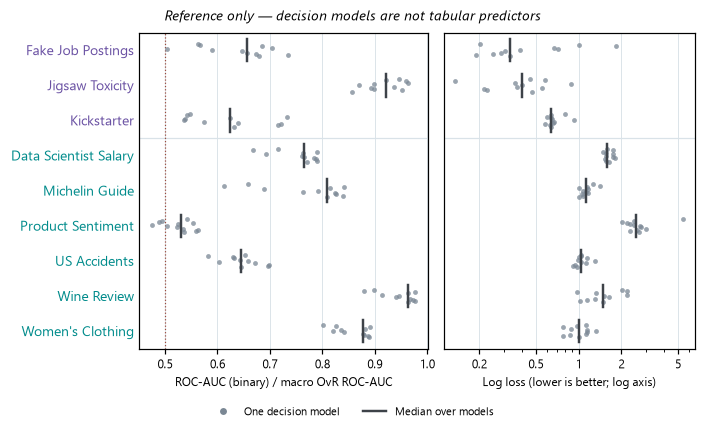

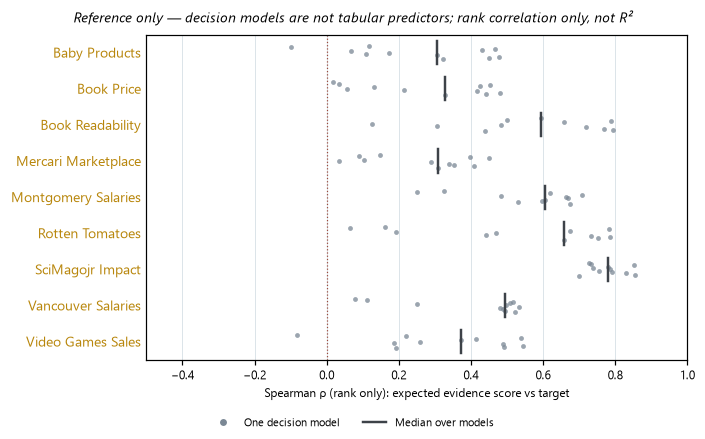

In [5]:
from src.evaluation.zero_shot import REFERENCE_LABEL, direct_scores, structured_references, summary_table
from src.visualize.zero_shot import direct_score_figures
report_section("5. Appendix candidate: decision models scored directly on the test rows")
record(REFERENCE_LABEL + ". Stored decision probabilities are scored without fitting on the shared outer-test rows; test labels are used only for this after-the-fact description and never for selection.", "Evidence boundary")
direct = direct_scores()
references, reference_status = structured_references(folds)
direct_summary = summary_table(direct)
display_table("Direct scores: median and range over decision models (reference only)", direct_summary.round(3), preview_rows=12)
record(direct_summary, "Direct decision-model scores per dataset (median and range over models; reference only)")
record(direct.drop(columns="label"), "Every direct score, coverage and pending artifact (reference only)")
record(reference_status, "Exp 4 predictor references for the direct-score figure")
for fig, name, caption in direct_score_figures(direct, references):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

## Complete report

In [6]:
finish_report(NOTEBOOK, save.summary() + "\nOnly saved evidence was analysed; no inference, model training or live VSC changes were performed.")

exp04_decision_features

1. Scope, provenance and saved evidence


Notebook execution identity
{
  "code_sha256": "6593d29f281dcfc0d9eccf63a245c85c37280db4fed37cd9119be97f14ca2095",
  "git_head": "177427c62a24b29645898e7097943cd650c3b01f",
  "git_dirty": true,
  "tfm_library_pin": "1e5c8fe2c19d746fe3645c584df0c030bc03a117 dm-library (remotes/origin/HEAD)\n 60dffcdab88f20116fe0b17ac5aedfeb96aaa345 tfm-library (remotes/origin/HEAD)\n 211bc65a6155572fef808f2e7bd305c9395a441c vsc-library (heads/main-6-g211bc65)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.4",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


Saved result coverage
{
  "status": "no_completed_folds"
}


Prespecified headline metrics
{
  "binary_classification": "roc_auc",
  "multiclass_classification": "roc_auc_ovr_macro",
  "regression": "r2"
}


2. Decision features: Completion before performance


Complete/planned primary configurations
           